# Phase 5 — K-Means Customer Segmentation
**Project:** AI-Based Customer Segmentation and Purchasing Behaviour Analysis Using Machine Learning

## Objective
Use customer-level Recency, Frequency, and Monetary (RFM) features to group customers with K-Means. Evaluate candidate cluster counts using inertia (Elbow Method), silhouette score, Davies–Bouldin index, and Calinski–Harabasz score.

## Input
Place `Phase4_Customer_RFM.csv` in the same folder as this notebook, or update `INPUT_FILE` below.

## Modelling decisions
- Use only Recency, Frequency, Monetary as numeric clustering features.
- Apply `log1p` to Frequency and Monetary to reduce right-skew; Recency remains on its original scale.
- Standardize all three transformed features with `StandardScaler`.
- Compare K from 2 to 8. Use `random_state=42` and `n_init=10` for reproducibility.
- Choose a candidate K using metrics and cluster interpretability, not classification accuracy. There are no ground-truth segment labels.
- Monetary reflects retained positive purchase value; returns/cancellations were excluded in Phase 3.

In [1]:
import os
from pathlib import Path
# Work inside data/processed (found from the notebook folder upwards); paths below are relative to it.
for _d in [Path.cwd(), *Path.cwd().parents]:
    if (_d / "data" / "processed").is_dir():
        os.chdir(_d / "data" / "processed")
        break
print("Data folder:", Path.cwd().name)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANDOM_STATE = 42
INPUT_FILE = Path("Phase4_Customer_RFM.csv")
OUTPUT_DIR = Path("../../artifacts/phase_outputs/phase5_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(INPUT_FILE)
print("RFM dataset shape:", df.shape)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
display(df.head())

Data folder: processed


RFM dataset shape: (4338, 8)
pandas 2.3.2 | numpy 2.3.3 | scikit-learn 1.7.2


,CustomerID,Recency,Frequency,Monetary,TotalItems,DistinctProducts,Country,LastPurchaseDate
0,12346,326,1,77183.60,74215,1,United Kingdom,2011-01-18 10:01:00
1,12347,3,7,4310.00,2458,103,Iceland,2011-12-07 15:52:00
2,12348,76,4,1797.24,2341,22,Finland,2011-09-25 13:13:00
3,12349,19,1,1757.55,631,73,Italy,2011-11-21 09:51:00
4,12350,311,1,334.40,197,17,Norway,2011-02-02 16:01:00


In [2]:
# Validate the required columns and data
required = ["CustomerID", "Recency", "Frequency", "Monetary"]
missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if df[["Recency", "Frequency", "Monetary"]].isna().any().any():
    raise ValueError("Core RFM features contain missing values.")
if (df[["Recency", "Frequency", "Monetary"]] < 0).any().any():
    raise ValueError("RFM features contain negative values.")
if (df["Frequency"] < 1).any() or (df["Monetary"] <= 0).any():
    raise ValueError("Frequency or Monetary values are outside the expected range.")

rfm_features = df[["Recency", "Frequency", "Monetary"]].copy()
print("Customers:", len(df))
print("Duplicate customer IDs:", int(df["CustomerID"].duplicated().sum()))
display(rfm_features.describe().T)


Customers: 4338
Duplicate customer IDs: 0


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.00,18.0000,51.00,142.7500,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688080,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


In [3]:
# Reduce skew in Frequency and Monetary, then scale features
X_features = rfm_features.copy()
X_features["Frequency"] = np.log1p(X_features["Frequency"])
X_features["Monetary"] = np.log1p(X_features["Monetary"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)
print("Scaled feature matrix shape:", X_scaled.shape)


Scaled feature matrix shape: (4338, 3)


In [4]:
# Evaluate K=2..8
results = []
models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    models[k] = model
    sizes = pd.Series(labels).value_counts()
    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, labels),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max()
    })

evaluation = pd.DataFrame(results)
display(evaluation.round(4))
print("Best K by silhouette (max):", int(evaluation.loc[evaluation["Silhouette Score"].idxmax(), "K"]))
print("Best K by Davies-Bouldin (min):", int(evaluation.loc[evaluation["Davies-Bouldin Index"].idxmin(), "K"]))
print("Best K by Calinski-Harabasz (max):", int(evaluation.loc[evaluation["Calinski-Harabasz Score"].idxmax(), "K"]))

,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Smallest Cluster,Largest Cluster
0,2,6874.0473,0.4063,0.9153,3872.9560,1820,2518
1,3,4299.2010,0.4157,0.8249,4393.7259,980,2038
2,4,3242.9348,0.3794,0.8599,4352.8451,573,1450
3,5,2760.6831,0.3435,0.9410,4023.2453,324,1201
4,6,2396.8027,0.3316,0.9692,3837.9672,324,1100
5,7,2167.0871,0.3008,1.0185,3613.0047,205,960
6,8,1961.6506,0.2995,1.0003,3485.1702,173,888


Best K by silhouette (max): 3
Best K by Davies-Bouldin (min): 3
Best K by Calinski-Harabasz (max): 3


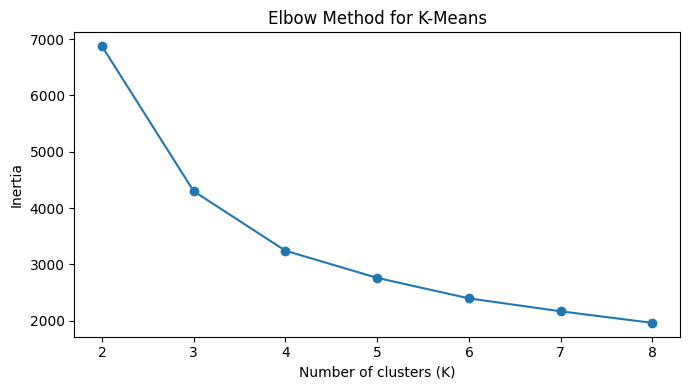

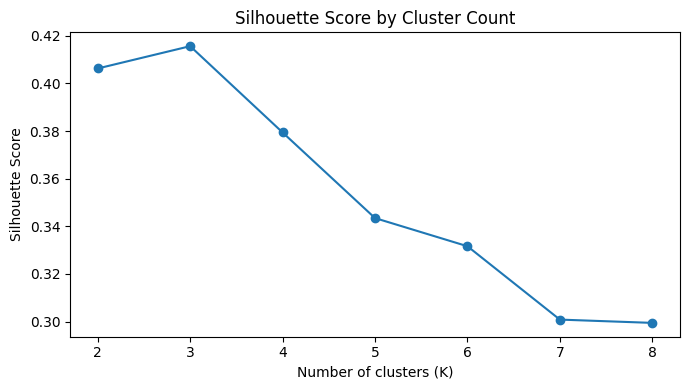

In [5]:
# Elbow plot
plt.figure(figsize=(7, 4))
plt.plot(evaluation["K"], evaluation["Inertia"], marker="o")
plt.xticks(evaluation["K"])
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "elbow_method.png", dpi=150)
plt.show()

# Silhouette plot
plt.figure(figsize=(7, 4))
plt.plot(evaluation["K"], evaluation["Silhouette Score"], marker="o")
plt.xticks(evaluation["K"])
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Cluster Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "silhouette_scores.png", dpi=150)
plt.show()

In [6]:
# Select the candidate with the highest silhouette score among tested K values.
# This is a metric-based starting point; business interpretability must also be checked.
best_k = int(evaluation.loc[evaluation["Silhouette Score"].idxmax(), "K"])
final_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = final_model.fit_predict(X_scaled)

# The final model must reproduce the evaluated model for the same K.
assert (df["Cluster"].to_numpy() == models[best_k].labels_).all()
best_row = evaluation.loc[evaluation["K"] == best_k].iloc[0]
assert df["Cluster"].value_counts().min() == best_row["Smallest Cluster"]
assert df["Cluster"].value_counts().max() == best_row["Largest Cluster"]

cluster_profiles = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Recency_Median=("Recency", "median"),
    Frequency_Median=("Frequency", "median"),
    Monetary_Median=("Monetary", "median"),
    Recency_Mean=("Recency", "mean"),
    Frequency_Mean=("Frequency", "mean"),
    Monetary_Mean=("Monetary", "mean")
).reset_index()
assert cluster_profiles["Customers"].sum() == len(df)

# Seed stability: compare the selected   solution with other random seeds (label-permutation invariant).
stability = {s: adjusted_rand_score(df["Cluster"], KMeans(n_clusters=best_k, random_state=s, n_init=10).fit_predict(X_scaled))
             for s in [0, 1, 7, 123, 2024]}
print("Selected candidate K:", best_k)
print("Adjusted Rand Index vs other seeds:", {s: round(v, 4) for s, v in stability.items()})
display(cluster_profiles.round(2))

Selected candidate K: 3
Adjusted Rand Index vs other seeds: {0: 0.9993, 1: 0.9993, 7: 0.9993, 123: 0.9993, 2024: 0.9993}


,Cluster,Customers,Recency_Median,Frequency_Median,Monetary_Median,Recency_Mean,Frequency_Mean,Monetary_Mean
0,0,2038,46.0,2.0,508.80,55.31,2.05,612.67
1,1,980,253.0,1.0,290.46,255.70,1.39,397.03
2,2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04


## Profile-based segment interpretation
Cluster IDs are arbitrary, so names are assigned from each cluster's RFM **profile**, not its ID. The rule compares each
cluster's median Recency, Frequency and Monetary with the population median (strict inequalities, so a cluster whose
median merely equals the population median is not called "frequent" or "high-spend"). Phase 7 applies the same rule.
The names are descriptive labels for this dataset only; they are not ground truth.

In [7]:
overall = df[["Recency", "Frequency", "Monetary"]].median()

def suggest_name(row):
    recent = row["Recency_Median"] < overall["Recency"]
    frequent = row["Frequency_Median"] > overall["Frequency"]
    high_spend = row["Monetary_Median"] > overall["Monetary"]
    if recent and frequent and high_spend:
        return "Recent, Frequent, High-Spend Customers"
    if recent and frequent:
        return "Recent, Frequent Customers"
    if recent and high_spend:
        return "Recent, High-Spend Customers"
    if frequent and high_spend:
        return "Frequent, High-Spend Customers"
    if row["Recency_Median"] > overall["Recency"] and row["Frequency_Median"] < overall["Frequency"]:
        return "At-Risk / Inactive, Low-Frequency Customers"
    if row["Recency_Median"] > overall["Recency"]:
        return "Less-Recent Customers"
    return "Occasional / Lower-Spend Customers"

cluster_profiles["Segment"] = cluster_profiles.apply(suggest_name, axis=1)
print("Population medians:", overall.to_dict())
assert cluster_profiles["Segment"].is_unique, "Two clusters received the same descriptive name"
df["Segment"] = df["Cluster"].map(cluster_profiles.set_index("Cluster")["Segment"])
display(cluster_profiles.round(2))

Population medians: {'Recency': 51.0, 'Frequency': 2.0, 'Monetary': 668.5699999999999}


,Cluster,Customers,Recency_Median,Frequency_Median,Monetary_Median,Recency_Mean,Frequency_Mean,Monetary_Mean,Segment
0,0,2038,46.0,2.0,508.80,55.31,2.05,612.67,Occasional / Lower-Spend Customers
1,1,980,253.0,1.0,290.46,255.70,1.39,397.03,"At-Risk / Inactive, Low-Frequency Customers"
2,2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,"Recent, Frequent, High-Spend Customers"


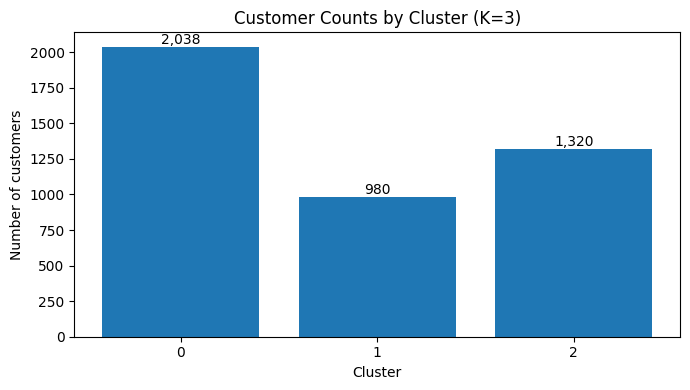

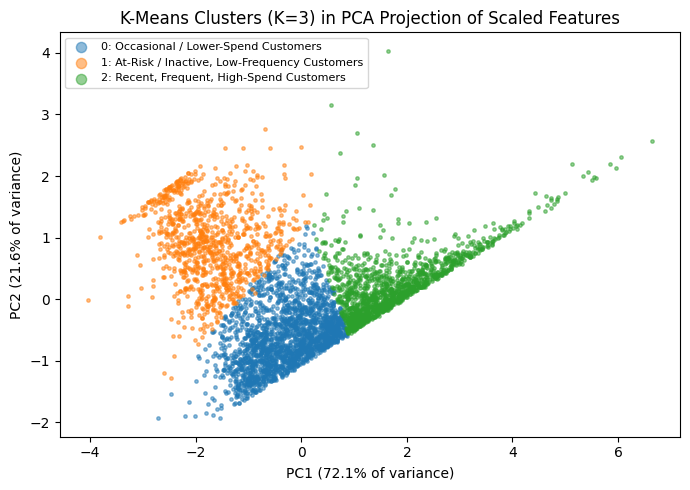

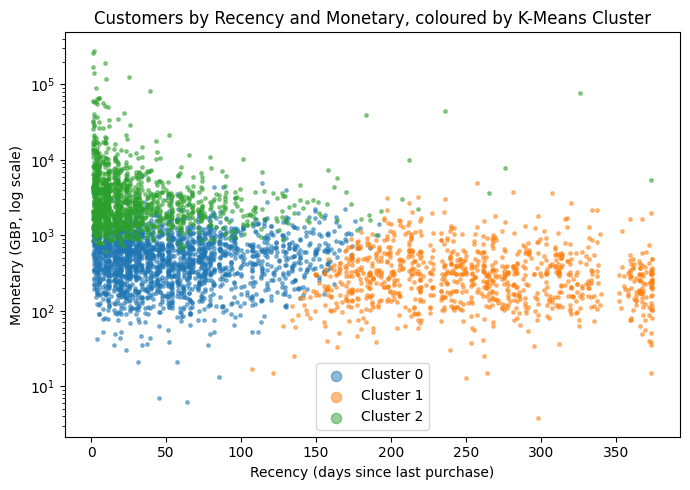

In [8]:
# Visualize customer counts per cluster
plt.figure(figsize=(7, 4))
plt.bar(cluster_profiles["Cluster"].astype(str), cluster_profiles["Customers"])
for x, n in zip(cluster_profiles["Cluster"].astype(str), cluster_profiles["Customers"]):
    plt.text(x, n, f"{n:,}", ha="center", va="bottom")
plt.xlabel("Cluster")
plt.ylabel("Number of customers")
plt.title(f"Customer Counts by Cluster (K={best_k})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_sizes.png", dpi=150)
plt.show()

# Cluster visualization 1: the clustering space projected onto its first two principal components
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
for c in sorted(df["Cluster"].unique()):
    m = df["Cluster"].to_numpy() == c
    plt.scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.5, label=f"{c}: {cluster_profiles.loc[cluster_profiles['Cluster'] == c, 'Segment'].iloc[0]}")
plt.xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% of variance)")
plt.ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% of variance)")
plt.title(f"K-Means Clusters (K={best_k}) in PCA Projection of Scaled Features")
plt.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_scatter_pca.png", dpi=150)
plt.show()

# Cluster visualization 2: original units, Recency vs Monetary (log scale)
plt.figure(figsize=(7, 5))
for c in sorted(df["Cluster"].unique()):
    sub = df[df["Cluster"] == c]
    plt.scatter(sub["Recency"], sub["Monetary"], s=6, alpha=0.5, label=f"Cluster {c}")
plt.yscale("log")
plt.xlabel("Recency (days since last purchase)")
plt.ylabel("Monetary (GBP, log scale)")
plt.title("Customers by Recency and Monetary, coloured by K-Means Cluster")
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_scatter_recency_monetary.png", dpi=150)
plt.show()

In [9]:
# Save outputs for the next phase and final report
evaluation.to_csv("Phase5_KMeans_Evaluation.csv", index=False, lineterminator="\n")
df.to_csv("Phase5_Customer_Clusters.csv", index=False, lineterminator="\n")
cluster_profiles.to_csv("Phase5_Cluster_Profiles.csv", index=False, lineterminator="\n")
print("Saved evaluation, customer labels, cluster profiles, and graphs in", OUTPUT_DIR)

Saved evaluation, customer labels, cluster profiles, and graphs in ..\..\artifacts\phase_outputs\phase5_outputs


## Interpretation notes and limitations
- Silhouette scores closer to 1 indicate better separation; values around 0 suggest overlapping clusters, and negative values may indicate poor assignments.
- Lower Davies–Bouldin is generally better; higher Calinski–Harabasz is generally better. Inertia always tends to decrease as K increases, so it must be interpreted with the elbow plot.
- Cluster labels (0, 1, 2, ...) are arbitrary IDs, not rankings.
- Describe each segment using its RFM profile. Lower Recency means more recent activity; higher Frequency means more invoices; higher Monetary means higher retained positive-purchase value.
- Do not call these clusters proven customer types until profiles have been interpreted. This is unsupervised learning, so accuracy is not an appropriate metric without ground-truth labels.
- The candidate K with the highest silhouette score is only a starting point. Review cluster sizes and whether the profiles are useful before finalizing K.